# HAM10000 Skin Cancer Project

- Dataset: **Skin Cancer MNIST: HAM10000** (`kmader/skin-cancer-mnist-ham10000`)
- Classification task: predict skin lesion diagnosis class (`dx`)
- Regression task: predict patient age (`age`)
- Models: VGG16 classification, VGG16 regression, ResNet50 classification, ResNet50 regression
- Evaluation: accuracy, weighted F1-score, confusion matrix, MSE, MAE, RMSE, R²
- Interpretability: Grad-CAM for all four models


In [6]:

# 1. Imports

import os
import glob
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 224
SUBSET_SIZE = 5000
BATCH_SIZE = 16
EPOCHS_HEAD = 20
EPOCHS_FINE_TUNE = 5
USE_PRETRAINED = True
NUM_WORKERS = 2

OUTPUT_DIR = "/kaggle/working/ham10000_pytorch_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output directory:", OUTPUT_DIR)


PyTorch version: 2.10.0+cu128
CUDA available: True
Using device: cuda
Output directory: /kaggle/working/ham10000_pytorch_outputs


## 2. Find HAM10000 files automatically

The dataset usually contains `HAM10000_metadata.csv` and image folders.


In [7]:
# 2. Find metadata CSV and image files

input_root = "/kaggle/input"

csv_files = glob.glob(input_root + "/**/*.csv", recursive=True)
print("CSV files found:")
for f in csv_files:
    print(" -", f)

metadata_path = None
for f in csv_files:
    if "metadata" in os.path.basename(f).lower():
        metadata_path = f
        break

if metadata_path is None:
    raise FileNotFoundError("Could not find HAM10000 metadata CSV. Add kmader/skin-cancer-mnist-ham10000.")

print("\nUsing metadata CSV:", metadata_path)
df = pd.read_csv(metadata_path)
display(df.head())
print("Columns:", df.columns.tolist())

image_files = glob.glob(input_root + "/**/*.jpg", recursive=True) + glob.glob(input_root + "/**/*.png", recursive=True)
print("\nNumber of image files found:", len(image_files))
for p in image_files[:5]:
    print(" -", p)


CSV files found:
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv

Using metadata CSV: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Number of image files found: 20030
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
 - /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027960.jpg


## 3. Prepare metadata

For this project:

- `dx` = classification target
- `age` = regression target


In [8]:
# 3. Prepare dataframe

df.columns = [c.strip().lower() for c in df.columns]

required_columns = ["image_id", "dx", "age"]
for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}. Found: {df.columns.tolist()}")

image_path_map = {}
for path in image_files:
    file_id = os.path.splitext(os.path.basename(path))[0]
    image_path_map[file_id] = path

df["image_path"] = df["image_id"].map(image_path_map)
df = df.dropna(subset=["image_path", "age"]).reset_index(drop=True)
df["age"] = df["age"].astype(float)

print("Rows after removing missing image/age:", len(df))
print("\nDiagnosis class counts:")
display(df["dx"].value_counts())
print("\nAge summary:")
display(df["age"].describe())
display(df.head())


Rows after removing missing image/age: 9958

Diagnosis class counts:


dx
nv       6660
mel      1111
bkl      1089
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


Age summary:


count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000
Name: age, dtype: float64

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/kmader/skin-cancer-mnis...


## 4. 5,000-image subset

The split is:

- 70% training
- 15% validation
- 15% testing

In [9]:
# 4. Select subset and split data

subset_size = min(SUBSET_SIZE, len(df))

df_subset, _ = train_test_split(
    df,
    train_size=subset_size,
    stratify=df["dx"],
    random_state=SEED
)
df_subset = df_subset.reset_index(drop=True)

label_encoder = LabelEncoder()
df_subset["dx_label"] = label_encoder.fit_transform(df_subset["dx"])
class_names = list(label_encoder.classes_)
NUM_CLASSES = len(class_names)

print("Subset size:", len(df_subset))
print("Class names:", class_names)
print("Number of classes:", NUM_CLASSES)
display(df_subset["dx"].value_counts())

train_df, temp_df = train_test_split(
    df_subset,
    test_size=0.30,
    stratify=df_subset["dx_label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["dx_label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Subset size: 5000
Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


dx
nv       3344
mel       558
bkl       547
bcc       258
akiec     164
vasc       71
df         58
Name: count, dtype: int64

Train: 3500
Validation: 750
Test: 750


## 5. Normalize age for regression

The regression model learns normalized age. During evaluation, predictions are converted back to real age.


In [10]:
# 5. Normalize age

age_mean = train_df["age"].mean()
age_std = train_df["age"].std()

print("Training age mean:", age_mean)
print("Training age std:", age_std)

for split_df in [train_df, val_df, test_df]:
    split_df["age_norm"] = (split_df["age"] - age_mean) / age_std

display(train_df.head())


Training age mean: 52.04857142857143
Training age std: 17.056231855686427


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,dx_label,age_norm
0,HAM_0000865,ISIC_0028826,bkl,consensus,70.0,male,abdomen,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2,1.052485
1,HAM_0000222,ISIC_0027658,nv,histo,10.0,female,lower extremity,/kaggle/input/datasets/kmader/skin-cancer-mnis...,5,-2.465291
2,HAM_0007422,ISIC_0024862,nv,histo,85.0,male,genital,/kaggle/input/datasets/kmader/skin-cancer-mnis...,5,1.931929
3,HAM_0002015,ISIC_0033954,nv,histo,30.0,female,lower extremity,/kaggle/input/datasets/kmader/skin-cancer-mnis...,5,-1.292699
4,HAM_0000259,ISIC_0024477,bkl,histo,60.0,male,back,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2,0.466189


## 6. PyTorch Dataset and DataLoaders

This section replaces TensorFlow `tf.data` with PyTorch `Dataset` and `DataLoader`.


In [11]:
# 6. PyTorch Dataset and transforms

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.08, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, task, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.task = task
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.task == "classification":
            label = torch.tensor(int(row["dx_label"]), dtype=torch.long)
        elif self.task == "regression":
            label = torch.tensor([float(row["age_norm"])], dtype=torch.float32)
        else:
            raise ValueError("task must be classification or regression")

        return image, label

def make_dataloader(dataframe, task, training=False):
    dataset = HAM10000Dataset(
        dataframe=dataframe,
        task=task,
        transform=train_transform if training else test_transform
    )
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

dataloaders = {}
for task in ["classification", "regression"]:
    dataloaders[(task, "train")] = make_dataloader(train_df, task, training=True)
    dataloaders[(task, "val")] = make_dataloader(val_df, task, training=False)
    dataloaders[(task, "test")] = make_dataloader(test_df, task, training=False)

print("DataLoaders are ready.")


DataLoaders are ready.


## 7. Show sample images


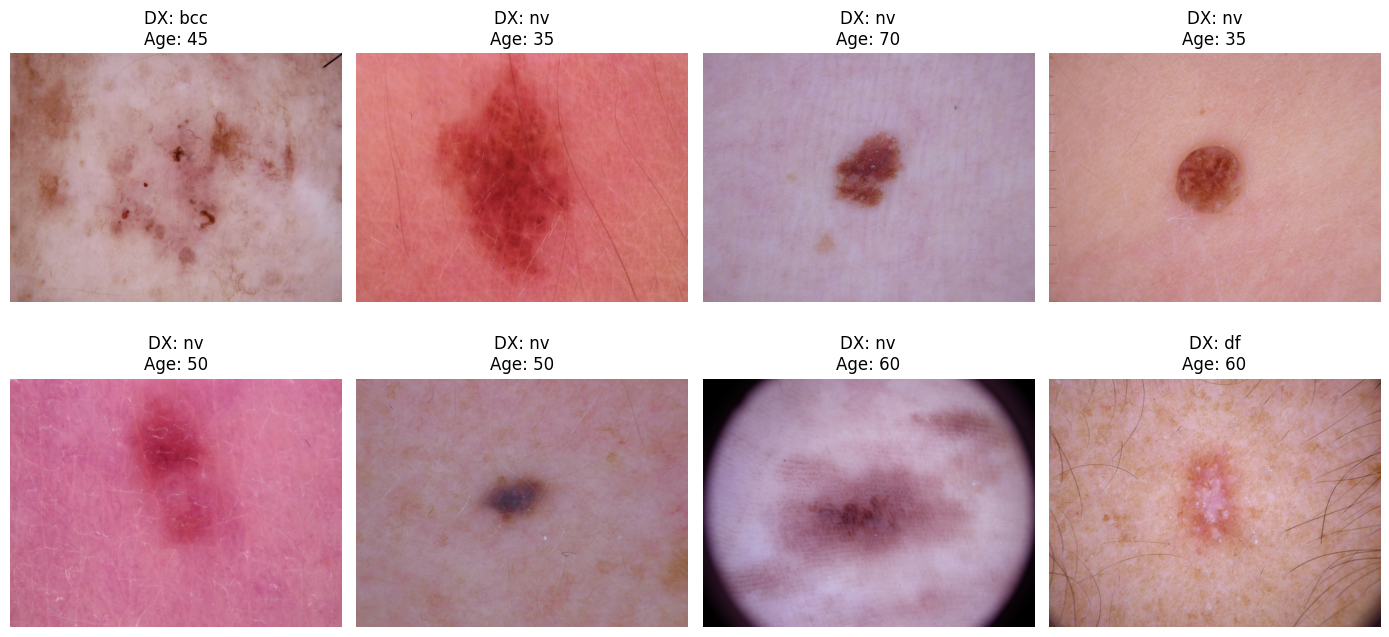

In [12]:
# 7. Show sample images

def show_samples(dataframe, n=8):
    sample_df = dataframe.sample(n=n, random_state=SEED)
    plt.figure(figsize=(14, 7))

    for i, row in enumerate(sample_df.itertuples()):
        image = Image.open(row.image_path).convert("RGB")
        plt.subplot(2, 4, i + 1)
        plt.imshow(image)
        plt.title(f"DX: {row.dx}\nAge: {row.age:.0f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(train_df, n=8)


## 8. Build VGG16 and ResNet50 models.


In [13]:
# 8. Build VGG16 and ResNet50 models 

def build_model(backbone_name, task):
   
    if task == "classification":
        output_dim = NUM_CLASSES
    elif task == "regression":
        output_dim = 1
    else:
        raise ValueError("task must be 'classification' or 'regression'")

    if backbone_name == "vgg":
        if USE_PRETRAINED:
            weights = models.VGG16_Weights.IMAGENET1K_V1
        else:
            weights = None

        model = models.vgg16(weights=weights)

        # Freeze VGG feature extractor first
        for param in model.features.parameters():
            param.requires_grad = False

      
        model.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        model.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(512, output_dim)
        )

    elif backbone_name == "resnet":
        if USE_PRETRAINED:
            weights = models.ResNet50_Weights.IMAGENET1K_V2
        else:
            weights = None

        model = models.resnet50(weights=weights)

        # Freeze ResNet backbone first
        for param in model.parameters():
            param.requires_grad = False

        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(0.35),
            nn.Linear(in_features, output_dim)
        )

    else:
        raise ValueError("backbone_name must be 'vgg' or 'resnet'")

    model = model.to(DEVICE)

    return model


def set_fine_tuning(model, backbone_name):
    
    if backbone_name == "vgg":
        # Fine-tune last VGG convolution block
        for param in model.features[-8:].parameters():
            param.requires_grad = True

    elif backbone_name == "resnet":
        # Fine-tune ResNet layer4
        for param in model.layer4.parameters():
            param.requires_grad = True

    return model


def get_loss_function(task):
    if task == "classification":
        return nn.CrossEntropyLoss()
    elif task == "regression":
        return nn.MSELoss()
    else:
        raise ValueError("task must be 'classification' or 'regression'")


def get_optimizer(model, learning_rate):
    return optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate
    )

## 9. Training and validation loops


In [14]:

# 9. Training and validation functions 

def train_one_epoch(model, dataloader, criterion, optimizer, task):
    model.train()
    running_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in dataloader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        if task == "classification":
            preds = torch.argmax(outputs, dim=1)
            all_true.extend(labels.detach().cpu().numpy())
            all_pred.extend(preds.detach().cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)

    if task == "classification":
        epoch_acc = accuracy_score(all_true, all_pred)
        return epoch_loss, epoch_acc

    return epoch_loss, None

def validate_one_epoch(model, dataloader, criterion, task):
    model.eval()
    running_loss = 0.0
    all_true, all_pred = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)

            if task == "classification":
                preds = torch.argmax(outputs, dim=1)
                all_true.extend(labels.detach().cpu().numpy())
                all_pred.extend(preds.detach().cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)

    if task == "classification":
        epoch_acc = accuracy_score(all_true, all_pred)
        return epoch_loss, epoch_acc

    return epoch_loss, None


## 10. Train one model

Each model trains in two stages:

1. Train only the new head, learning rate `1e-4`
2. Fine-tune last backbone layers, learning rate `1e-5`


In [15]:
# 10. Train one model

def train_one_model(backbone_name, task):
    print("=" * 70)
    print(f"Training {backbone_name.upper()} for {task.upper()}")
    print("=" * 70)

    model = build_model(backbone_name, task)
    criterion = get_loss_function(task)

    train_loader = dataloaders[(task, "train")]
    val_loader = dataloaders[(task, "val")]

    model_name = f"{backbone_name}_{task}"
    model_path = os.path.join(OUTPUT_DIR, f"{model_name}_best.pth")

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    best_val_loss = np.inf
    patience = 5
    patience_counter = 0

    print("\nStage 1: training only the new top/head layers")
    optimizer = get_optimizer(model, learning_rate=1e-4)

    for epoch in range(EPOCHS_HEAD):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, task)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, task)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if task == "classification":
            print(f"Epoch {epoch+1}/{EPOCHS_HEAD} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | Train acc: {train_acc:.4f} | Val acc: {val_acc:.4f}")
        else:
            print(f"Epoch {epoch+1}/{EPOCHS_HEAD} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), model_path)
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping during Stage 1.")
            break

    print("\nStage 2: fine-tuning last backbone layers")
    model = set_fine_tuning(model, backbone_name)
    optimizer = get_optimizer(model, learning_rate=1e-5)
    patience_counter = 0

    for epoch in range(EPOCHS_FINE_TUNE):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, task)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, task)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if task == "classification":
            print(f"Fine-tune epoch {epoch+1}/{EPOCHS_FINE_TUNE} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | Train acc: {train_acc:.4f} | Val acc: {val_acc:.4f}")
        else:
            print(f"Fine-tune epoch {epoch+1}/{EPOCHS_FINE_TUNE} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), model_path)
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping during Stage 2.")
            break

    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    print(f"Best model saved at: {model_path}")

    return model, history, model_path


## 11. Train all four required models


In [16]:
# 11. Train all four models

trained_models = {}
training_histories = {}
saved_model_paths = {}

experiments = [
    ("vgg", "classification"),
    ("vgg", "regression"),
    ("resnet", "classification"),
    ("resnet", "regression")
]

for backbone_name, task in experiments:
    model, history, model_path = train_one_model(backbone_name, task)
    trained_models[(backbone_name, task)] = model
    training_histories[(backbone_name, task)] = history
    saved_model_paths[(backbone_name, task)] = model_path

print("All four models are trained.")


Training VGG for CLASSIFICATION
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 226MB/s]  



Stage 1: training only the new top/head layers
Epoch 1/20 | Train loss: 1.5422 | Val loss: 1.2981 | Train acc: 0.5926 | Val acc: 0.6693
Epoch 2/20 | Train loss: 1.2267 | Val loss: 1.1701 | Train acc: 0.6686 | Val acc: 0.6693
Epoch 3/20 | Train loss: 1.1508 | Val loss: 1.1208 | Train acc: 0.6689 | Val acc: 0.6693
Epoch 4/20 | Train loss: 1.1042 | Val loss: 1.0880 | Train acc: 0.6691 | Val acc: 0.6693
Epoch 5/20 | Train loss: 1.0802 | Val loss: 1.0626 | Train acc: 0.6700 | Val acc: 0.6707
Epoch 6/20 | Train loss: 1.0532 | Val loss: 1.0413 | Train acc: 0.6717 | Val acc: 0.6707
Epoch 7/20 | Train loss: 1.0337 | Val loss: 1.0237 | Train acc: 0.6731 | Val acc: 0.6707
Epoch 8/20 | Train loss: 1.0162 | Val loss: 1.0093 | Train acc: 0.6757 | Val acc: 0.6720
Epoch 9/20 | Train loss: 0.9999 | Val loss: 0.9956 | Train acc: 0.6760 | Val acc: 0.6720
Epoch 10/20 | Train loss: 0.9907 | Val loss: 0.9837 | Train acc: 0.6743 | Val acc: 0.6707
Epoch 11/20 | Train loss: 0.9773 | Val loss: 0.9738 | Train a

100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s] 



Stage 1: training only the new top/head layers
Epoch 1/20 | Train loss: 1.2369 | Val loss: 1.0617 | Train acc: 0.6477 | Val acc: 0.6693
Epoch 2/20 | Train loss: 1.0429 | Val loss: 0.9899 | Train acc: 0.6691 | Val acc: 0.6693
Epoch 3/20 | Train loss: 0.9865 | Val loss: 0.9385 | Train acc: 0.6717 | Val acc: 0.6720
Epoch 4/20 | Train loss: 0.9452 | Val loss: 0.9055 | Train acc: 0.6777 | Val acc: 0.6787
Epoch 5/20 | Train loss: 0.9070 | Val loss: 0.8780 | Train acc: 0.6846 | Val acc: 0.6840
Epoch 6/20 | Train loss: 0.8817 | Val loss: 0.8581 | Train acc: 0.6900 | Val acc: 0.6800
Epoch 7/20 | Train loss: 0.8655 | Val loss: 0.8427 | Train acc: 0.6911 | Val acc: 0.6973
Epoch 8/20 | Train loss: 0.8566 | Val loss: 0.8280 | Train acc: 0.6991 | Val acc: 0.6933
Epoch 9/20 | Train loss: 0.8410 | Val loss: 0.8102 | Train acc: 0.7057 | Val acc: 0.6947
Epoch 10/20 | Train loss: 0.8262 | Val loss: 0.7928 | Train acc: 0.7023 | Val acc: 0.7147
Epoch 11/20 | Train loss: 0.8126 | Val loss: 0.7927 | Train a

## 12. Plot training curves


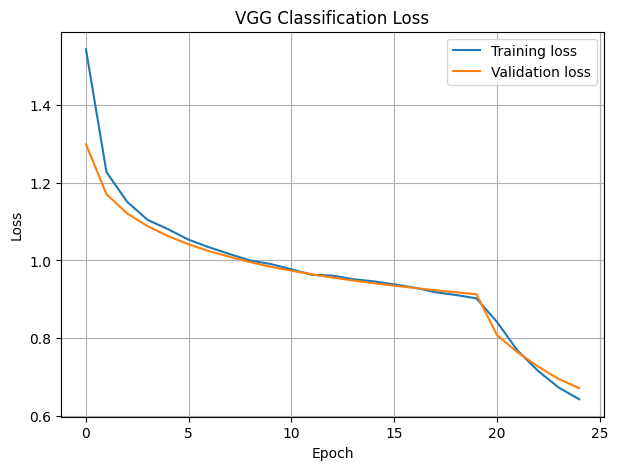

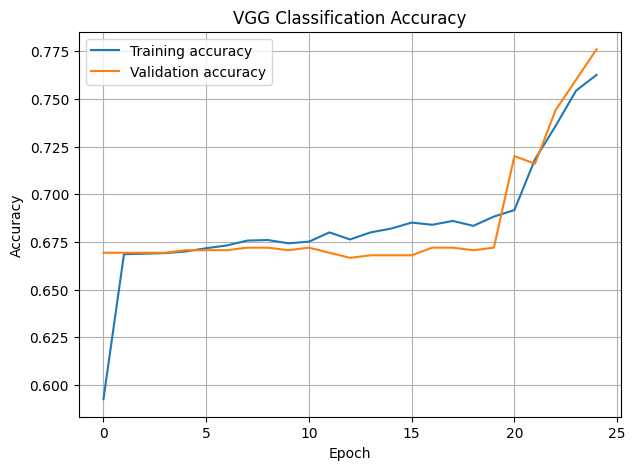

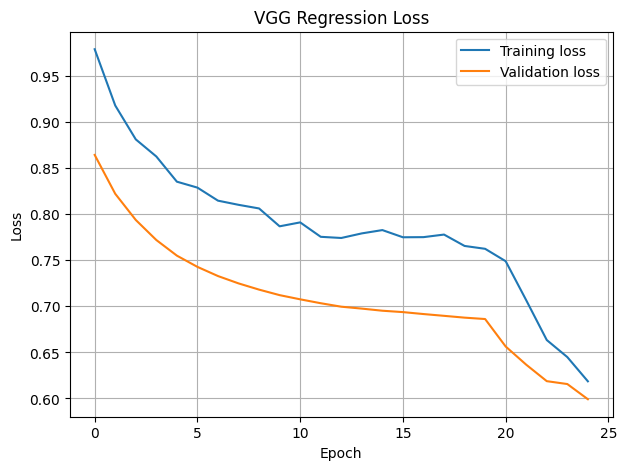

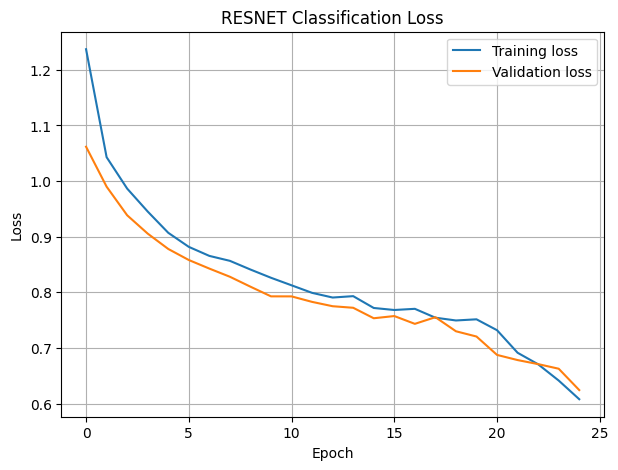

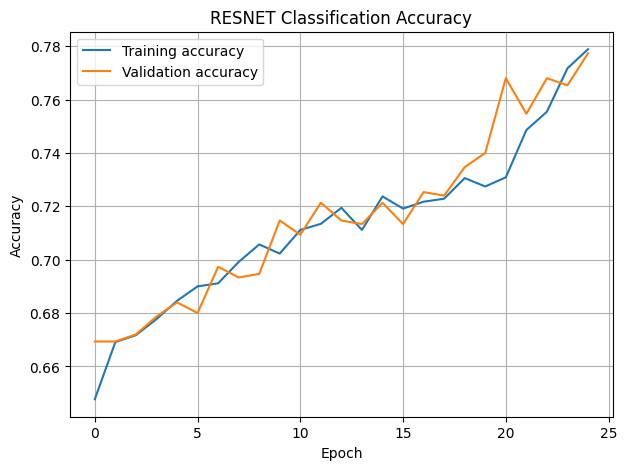

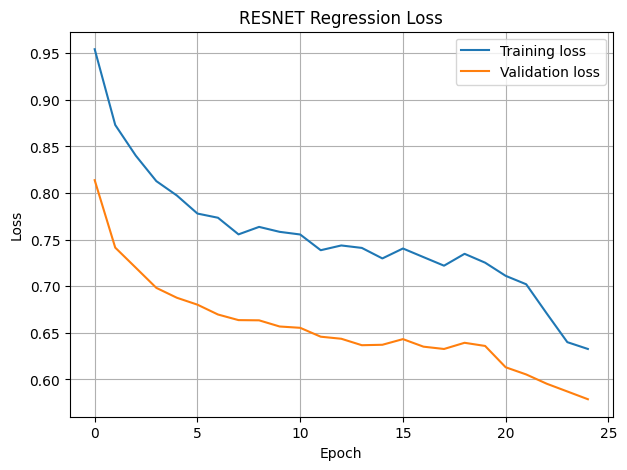

In [17]:
# ============================================================
# 12. Plot training curves
# ============================================================

def plot_history(backbone_name, task):
    history = training_histories[(backbone_name, task)]

    plt.figure(figsize=(7, 5))
    plt.plot(history["train_loss"], label="Training loss")
    plt.plot(history["val_loss"], label="Validation loss")
    plt.title(f"{backbone_name.upper()} {task.title()} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    if task == "classification":
        plt.figure(figsize=(7, 5))
        plt.plot(history["train_acc"], label="Training accuracy")
        plt.plot(history["val_acc"], label="Validation accuracy")
        plt.title(f"{backbone_name.upper()} Classification Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(True)
        plt.show()

for backbone_name, task in experiments:
    plot_history(backbone_name, task)


## 13. Evaluation functions


In [18]:
# 13. Evaluation functions

def evaluate_classification(model, backbone_name):
    model.eval()
    test_loader = dataloaders[("classification", "test")]
    all_true, all_pred = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            all_true.extend(labels.numpy())
            all_pred.extend(preds.cpu().numpy())

    acc = accuracy_score(all_true, all_pred)
    f1_weighted = f1_score(all_true, all_pred, average="weighted")
    cm = confusion_matrix(all_true, all_pred)

    print(f"\n{backbone_name.upper()} Classification Results")
    print("Accuracy:", acc)
    print("Weighted F1-score:", f1_weighted)
    print("\nClassification report:")
    print(classification_report(all_true, all_pred, target_names=class_names))

    plt.figure(figsize=(8, 6))
    plt.imshow(cm)
    plt.title(f"{backbone_name.upper()} Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(range(NUM_CLASSES), class_names, rotation=45)
    plt.yticks(range(NUM_CLASSES), class_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)

    plt.colorbar()
    plt.tight_layout()
    plt.show()

    return {
        "Model": backbone_name.upper(), "Task": "Classification",
        "Accuracy": acc, "F1_weighted": f1_weighted,
        "MSE": np.nan, "MAE": np.nan, "RMSE": np.nan, "R2": np.nan
    }

def evaluate_regression(model, backbone_name):
    model.eval()
    test_loader = dataloaders[("regression", "test")]
    all_true_norm, all_pred_norm = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)

            all_true_norm.extend(labels.numpy().reshape(-1))
            all_pred_norm.extend(outputs.cpu().numpy().reshape(-1))

    all_true_norm = np.array(all_true_norm)
    all_pred_norm = np.array(all_pred_norm)

    y_true_age = (all_true_norm * age_std) + age_mean
    y_pred_age = (all_pred_norm * age_std) + age_mean

    mse = mean_squared_error(y_true_age, y_pred_age)
    mae = mean_absolute_error(y_true_age, y_pred_age)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true_age, y_pred_age)

    print(f"\n{backbone_name.upper()} Regression Results")
    print("MSE:", mse)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true_age, y_pred_age, alpha=0.5)
    plt.plot([y_true_age.min(), y_true_age.max()], [y_true_age.min(), y_true_age.max()], linestyle="--")
    plt.xlabel("True age")
    plt.ylabel("Predicted age")
    plt.title(f"{backbone_name.upper()} Regression: True vs Predicted Age")
    plt.grid(True)
    plt.show()

    return {
        "Model": backbone_name.upper(), "Task": "Regression",
        "Accuracy": np.nan, "F1_weighted": np.nan,
        "MSE": mse, "MAE": mae, "RMSE": rmse, "R2": r2
    }


## 14. Evaluate all models and save comparison table



VGG Classification Results
Accuracy: 0.7613333333333333
Weighted F1-score: 0.7332420996167688

Classification report:
              precision    recall  f1-score   support

       akiec       0.62      0.40      0.49        25
         bcc       0.62      0.46      0.53        39
         bkl       0.57      0.45      0.50        82
          df       0.00      0.00      0.00         9
         mel       0.51      0.31      0.39        83
          nv       0.81      0.95      0.88       501
        vasc       1.00      0.18      0.31        11

    accuracy                           0.76       750
   macro avg       0.59      0.39      0.44       750
weighted avg       0.73      0.76      0.73       750



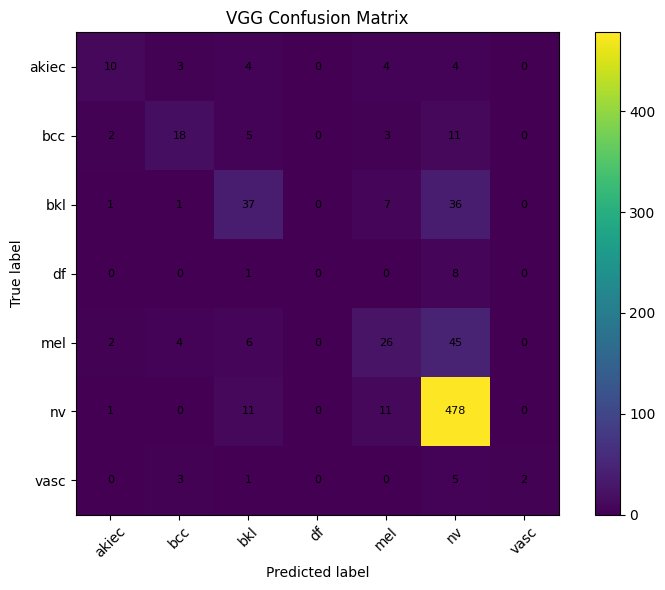


VGG Regression Results
MSE: 177.931638359274
MAE: 10.567894135080278
RMSE: 13.339101857294365
R2: 0.3677677525131767


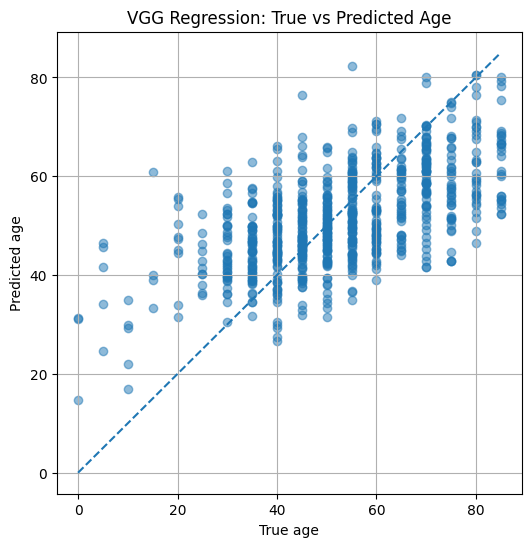


RESNET Classification Results
Accuracy: 0.7626666666666667
Weighted F1-score: 0.7351524684300986

Classification report:
              precision    recall  f1-score   support

       akiec       0.47      0.32      0.38        25
         bcc       0.55      0.56      0.56        39
         bkl       0.61      0.44      0.51        82
          df       0.00      0.00      0.00         9
         mel       0.44      0.27      0.33        83
          nv       0.83      0.96      0.89       501
        vasc       1.00      0.36      0.53        11

    accuracy                           0.76       750
   macro avg       0.56      0.42      0.46       750
weighted avg       0.73      0.76      0.74       750



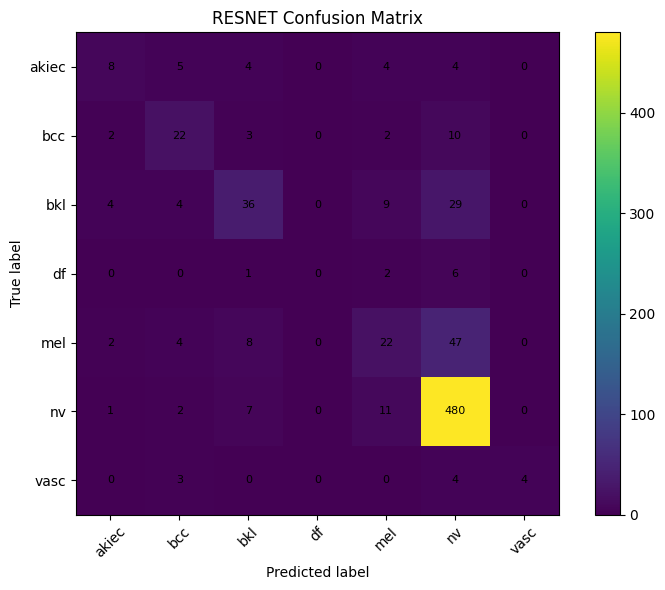


RESNET Regression Results
MSE: 188.33361908734022
MAE: 10.907041461069719
RMSE: 13.723469644639442
R2: 0.33080711013016806


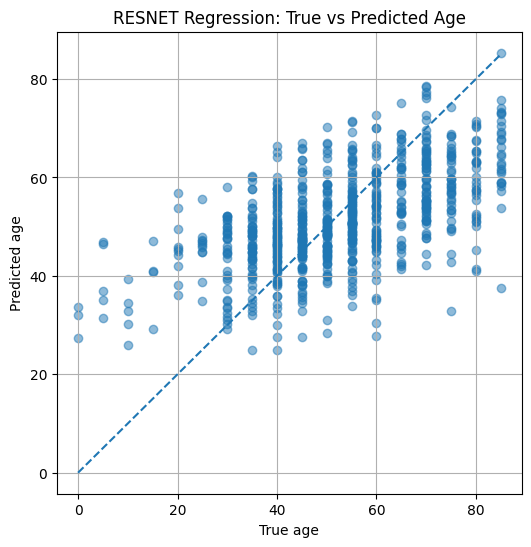

,Model,Task,Accuracy,F1_weighted,MSE,MAE,RMSE,R2
0,VGG,Classification,0.761333,0.733242,NaN,NaN,NaN,NaN
1,VGG,Regression,NaN,NaN,177.931638,10.567894,13.339102,0.367768
2,RESNET,Classification,0.762667,0.735152,NaN,NaN,NaN,NaN
3,RESNET,Regression,NaN,NaN,188.333619,10.907041,13.723470,0.330807


Comparison table saved to: /kaggle/working/ham10000_pytorch_outputs/final_comparison_table.csv


In [19]:
# 14. Final evaluation and comparison table

results = []

for backbone_name in ["vgg", "resnet"]:
    results.append(evaluate_classification(trained_models[(backbone_name, "classification")], backbone_name))
    results.append(evaluate_regression(trained_models[(backbone_name, "regression")], backbone_name))

results_df = pd.DataFrame(results)
display(results_df)

comparison_csv_path = os.path.join(OUTPUT_DIR, "final_comparison_table.csv")
results_df.to_csv(comparison_csv_path, index=False)
print("Comparison table saved to:", comparison_csv_path)


## 15. Grad-CAM helper functions

For classification, Grad-CAM focuses on the predicted lesion class.
For regression, Grad-CAM focuses on the age output.


In [20]:
# 15. Grad-CAM helper functions

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.forward_hook = target_layer.register_forward_hook(self.save_activation)
        self.backward_hook = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor, task):
        self.model.eval()
        self.model.zero_grad()
        output = self.model(input_tensor)

        if task == "classification":
            class_idx = torch.argmax(output, dim=1).item()
            score = output[:, class_idx]
        else:
            score = output[:, 0]

        score.backward()

        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze()
        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.detach().cpu().numpy()

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()

def get_target_layer(model, backbone_name):
    if backbone_name == "vgg":
        return model.features[-1]
    if backbone_name == "resnet":
        return model.layer4[-1].conv3
    raise ValueError("backbone_name must be vgg or resnet")

def load_image_for_gradcam(image_path):
    original_image = Image.open(image_path).convert("RGB")
    input_tensor = test_transform(original_image).unsqueeze(0).to(DEVICE)
    return original_image, input_tensor

def show_gradcam(model, image_path, backbone_name, task, title):
    original_image, input_tensor = load_image_for_gradcam(image_path)
    target_layer = get_target_layer(model, backbone_name)

    gradcam = GradCAM(model, target_layer)
    heatmap = gradcam.generate(input_tensor, task)
    gradcam.remove_hooks()

    heatmap_img = Image.fromarray(np.uint8(255 * heatmap)).resize((IMG_SIZE, IMG_SIZE))
    heatmap_resized = np.array(heatmap_img) / 255.0
    original_resized = original_image.resize((IMG_SIZE, IMG_SIZE))

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_resized)
    plt.title("Original image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized)
    plt.title("Grad-CAM heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original_resized)
    plt.imshow(heatmap_resized, alpha=0.45)
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


## 16. Grad-CAM for all four models


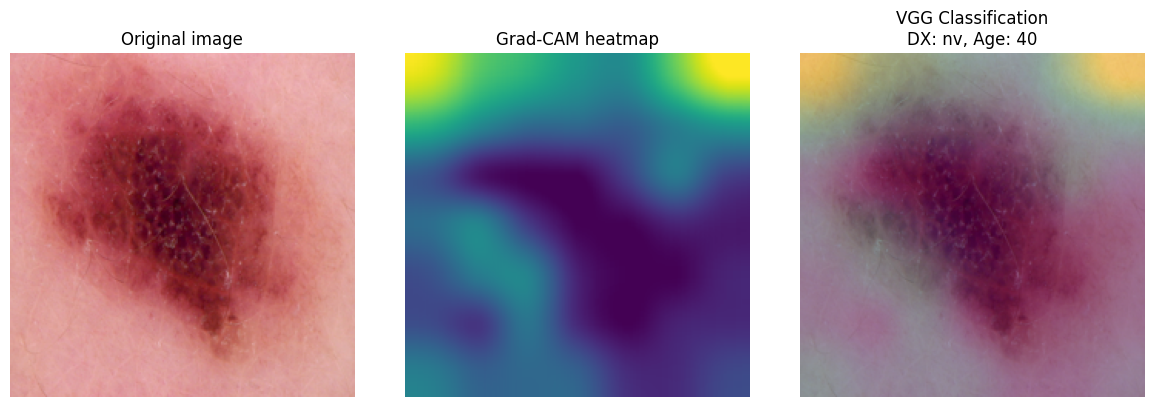

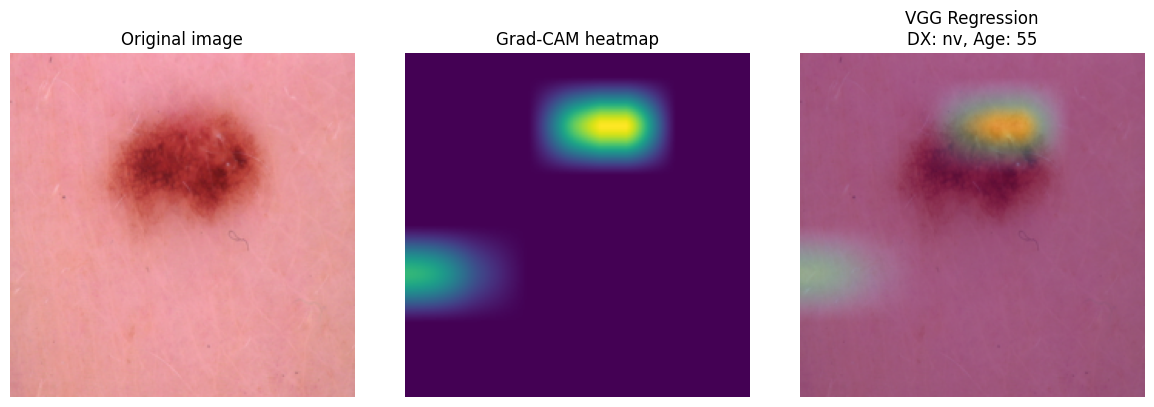

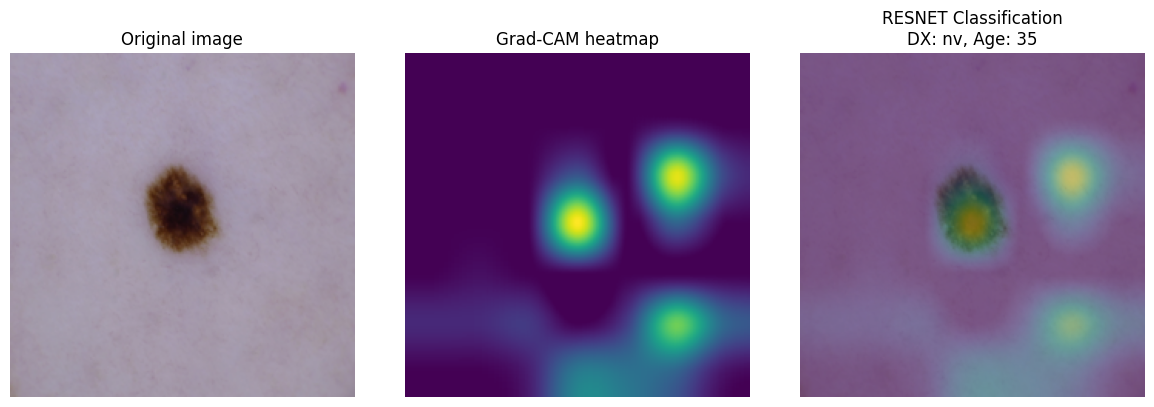

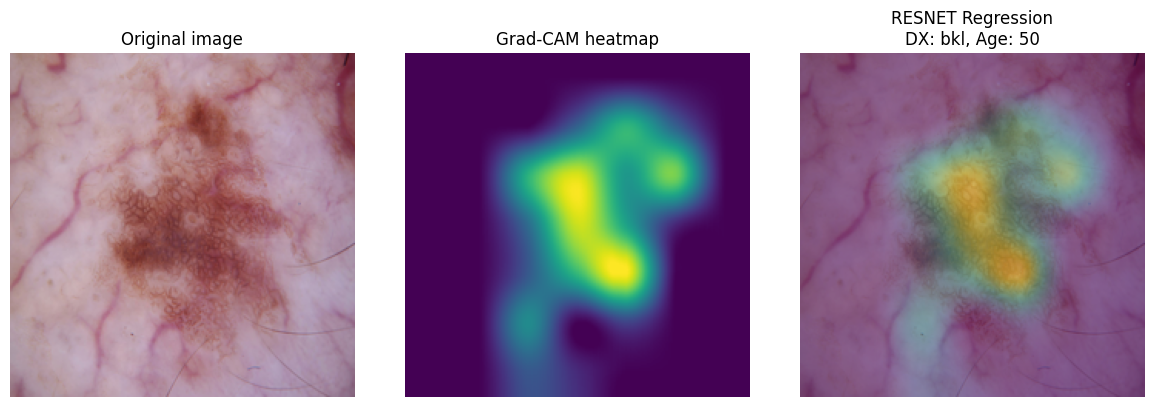

In [21]:
# 16. Grad-CAM for all four models

sample_rows = test_df.sample(n=4, random_state=SEED).reset_index(drop=True)

gradcam_settings = [
    ("vgg", "classification"),
    ("vgg", "regression"),
    ("resnet", "classification"),
    ("resnet", "regression")
]

for i, (backbone_name, task) in enumerate(gradcam_settings):
    row = sample_rows.iloc[i]
    model = trained_models[(backbone_name, task)]

    title = f"{backbone_name.upper()} {task.title()}\nDX: {row['dx']}, Age: {row['age']:.0f}"

    show_gradcam(
        model=model,
        image_path=row["image_path"],
        backbone_name=backbone_name,
        task=task,
        title=title
    )


## 17. Saved model paths


In [22]:
# 17. Print saved model paths

print("Saved model files:")
for key, path in saved_model_paths.items():
    print(key, "->", path)


Saved model files:
('vgg', 'classification') -> /kaggle/working/ham10000_pytorch_outputs/vgg_classification_best.pth
('vgg', 'regression') -> /kaggle/working/ham10000_pytorch_outputs/vgg_regression_best.pth
('resnet', 'classification') -> /kaggle/working/ham10000_pytorch_outputs/resnet_classification_best.pth
('resnet', 'regression') -> /kaggle/working/ham10000_pytorch_outputs/resnet_regression_best.pth


## 18. Report-ready summary


In [23]:
# 18.report summary text

summary_text = f"""
Dataset:
The Skin Cancer MNIST: HAM10000 dataset was used. A stratified subset of {SUBSET_SIZE} dermatoscopic images was selected.

Classification task:
The classification task predicts the skin lesion diagnosis class from the image.
The categorical classes are: {class_names}.

Regression task:
The regression task predicts patient age from the dermatoscopic image.
Age is a continuous numeric metadata value.

Models:
Four PyTorch models were trained:
1. VGG16 for lesion diagnosis classification
2. VGG16 for age regression
3. ResNet50 for lesion diagnosis classification
4. ResNet50 for age regression

Training protocol:
Images were resized to {IMG_SIZE}x{IMG_SIZE}.
Data augmentation was applied to training images.
ImageNet pretrained weights were used when internet was available.
First, the backbone was frozen and only the task-specific head was trained.
Then, the final convolutional block was fine-tuned.

Evaluation:
Classification models were evaluated using accuracy, weighted F1-score, confusion matrix, and classification report.
Regression models were evaluated using MSE, MAE, RMSE, and R2 score.
Grad-CAM was used to visualize important regions for all four trained models.
"""

print(summary_text)
summary_path = os.path.join(OUTPUT_DIR, "report_summary.txt")
with open(summary_path, "w") as f:
    f.write(summary_text)
print("Summary saved to:", summary_path)



Dataset:
The Skin Cancer MNIST: HAM10000 dataset was used. A stratified subset of 5000 dermatoscopic images was selected.

Classification task:
The classification task predicts the skin lesion diagnosis class from the image.
The categorical classes are: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'].

Regression task:
The regression task predicts patient age from the dermatoscopic image.
Age is a continuous numeric metadata value.

Models:
Four PyTorch models were trained:
1. VGG16 for lesion diagnosis classification
2. VGG16 for age regression
3. ResNet50 for lesion diagnosis classification
4. ResNet50 for age regression

Training protocol:
Images were resized to 224x224.
Data augmentation was applied to training images.
ImageNet pretrained weights were used when internet was available.
First, the backbone was frozen and only the task-specific head was trained.
Then, the final convolutional block was fine-tuned.

Evaluation:
Classification models were evaluated using accuracy, we

In [24]:
import shutil
import os

OUTPUT_DIR = "/kaggle/working/ham10000_pytorch_outputs"
ZIP_PATH = "/kaggle/working/ham10000_pytorch_outputs.zip"

if os.path.exists(OUTPUT_DIR):
    shutil.make_archive(
        base_name=ZIP_PATH.replace(".zip", ""),
        format="zip",
        root_dir=OUTPUT_DIR
    )
    print("ZIP file created:", ZIP_PATH)
else:
    print("Output folder does not exist yet.")

ZIP file created: /kaggle/working/ham10000_pytorch_outputs.zip
